<a href="https://colab.research.google.com/github/dzakirafiffakhriyanto/analisis-numerik-tugas-tugas/blob/main/25083010040_Dzaki_Rafif_Fakhriyanto_ETS_Analisis_Numerik.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ETS Analisis Numerik – Perhitungan Kapal
**Mata kuliah:** Analisis Numerik  |  **Prodi:** Sains Data  |  **Tanggal:** 19 Oktober 2026
**Nama / NPM:** Dzaki Rafif Fakhriyanto / 25083010040

(3 digit terakhir NPM = **040**, sehingga NPM3 = 40)

**Asumsi pemodelan**
1. Penampang prisma berbentuk segitiga dengan sudut 45° dan kedalaman 2 m, sehingga lebar dek $B = 2\times2 = 4$ m (label "3 m" pada gambar dipahami sebagai panjang sisi miring $2\sqrt2 \approx 2{,}83$ m).
2. Buritan elips: setiap irisan melintang tetap berbentuk segitiga 45°, dengan dasar mengikuti $y=2-2\sqrt{1-x^2}$.
3. Haluan ditutup pelat segitiga (dihitung sebagai baja).
4. Berat jenis baja $160$ kg/m² diperlakukan sebagai massa per satuan luas pelat.
5. Massa air $\rho = 1$ ton/m³ = 1000 kg/m³ dan $g = 9{,}81$ m/s².

## Langkah 0 – Import & parameter

In [1]:
import numpy as np
from scipy.optimize import brentq
import matplotlib.pyplot as plt

NPM3 = 40                      # 3 digit terakhir NPM = 040
RHO  = 1000.0                  # massa jenis air (kg/m3) = 1 ton/m3
G    = 9.81
LEBAR, DALAM = 4.0, 2.0        # lebar dek & kedalaman penampang segitiga (45 derajat -> 2*2)
L_PRISMA = 6.0                 # panjang bagian prisma (m)
ST   = 160.0                   # berat jenis baja (kg/m2)
MUATAN_TON = NPM3 * 100.0      # sesuai soal: tiga digit terakhir NPM x 100 ton = 4000 ton
MUATAN_KG  = MUATAN_TON * 1000

## Langkah 1 – Fungsi bantu: integral numerik Simpson 1/3

In [2]:
def simpson(f, a, b, n=2000):
    if n % 2: n += 1
    x = np.linspace(a, b, n+1); y = f(x); h = (b-a)/n
    return h/3*(y[0] + y[-1] + 4*y[1:-1:2].sum() + 2*y[2:-1:2].sum())

## Langkah 2 – Model geometri
- Kunci lunas buritan: $y=2-2\sqrt{1-x^2}$ (dari $4x^2+(y-2)^2=4$)
- Penampang tiap titik = segitiga 45°, luas $=t^2$ dengan $t=2\sqrt{1-x^2}$

In [3]:
h_k = lambda x: 2 - 2*np.sqrt(1 - x**2)                    # tinggi lunas (keel) di buritan
t_  = lambda x: 2*np.sqrt(np.clip(1 - x**2, 0, None))      # kedalaman penampang segitiga di x

## Soal 1 – Volume total & gaya apung maksimum

**Diketahui**
- Haluan: prisma segitiga, panjang $L = 6$ m, kedalaman $D = 2$ m, lebar dek $B = 4$ m.
- Buritan: elips $4x^2+(y-2)^2=4$, sehingga dasar buritan $h_k(x)=2-2\sqrt{1-x^2}$ untuk $0\le x\le 1$ m.
- Massa jenis air $\rho = 1000$ kg/m³.

**Ditanya**
Volume total kapal $V_{total}$ dan gaya apung maksimum $F_{max}$.

**Dijawab**
1. Volume prisma: $V_p = \tfrac12\, B\, D\, L$.
2. Kedalaman penampang buritan di posisi $x$: $t(x)=D-h_k(x)=2\sqrt{1-x^2}$. Penampangnya segitiga lebar $2t$ dan tinggi $t$, sehingga luasnya $A(x)=t(x)^2=4(1-x^2)$.
3. Volume buritan: $V_b=\int_0^1 A(x)\,dx=\int_0^1 4(1-x^2)\,dx$. Secara numerik memakai Simpson 1/3:
$$\int_a^b f(x)\,dx \approx \frac{h}{3}\Big[f_0+4\sum f_{ganjil}+2\sum f_{genap}+f_n\Big]$$
4. $V_{total}=V_p+V_b$, dan menurut Hukum Archimedes gaya apung maksimum terjadi saat seluruh lambung tercelup: $F_{max}=\rho\, V_{total}$.

In [4]:
V_prisma  = 0.5*LEBAR*DALAM*L_PRISMA                       # luas segitiga x panjang
V_buritan = simpson(lambda x: t_(x)**2, 0, 1)              # integral luas penampang
V_total   = V_prisma + V_buritan
F_max_ton = RHO*V_total/1000
print("V prisma  =", V_prisma, "m3")
print("V buritan =", round(V_buritan,4), "m3 (eksak 8/3)")
print("V total   =", round(V_total,4), "m3")
print("Gaya apung maks =", round(F_max_ton,3), "ton-gaya =", round(RHO*V_total*G/1000,1), "kN")

V prisma  = 24.0 m3
V buritan = 2.6667 m3 (eksak 8/3)
V total   = 26.6667 m3
Gaya apung maks = 26.667 ton-gaya = 261.6 kN


**Kesimpulan dan Interpretasi**:

- $V_p = 24$ m³, $V_b = 2{,}667$ m³ (sesuai nilai eksak $8/3$), sehingga **$V_{total} = 26{,}667$ m³**.
- **Gaya apung maksimum $= 26{,}667$ ton-gaya** (≈ 261,6 kN).

Artinya, kapal hanya mampu menahan berat total (kapal beserta muatan) sebesar 26,67 ton sebelum seluruh lambungnya terbenam. Bagian prisma menyumbang sekitar 90% dari volume, sedangkan buritan hanya sekitar 10%. Kesesuaian hasil numerik dengan nilai eksak $8/3$ menunjukkan bahwa metode Simpson 1/3 akurat untuk kasus ini.

## Soal 2 – Kurva draft (x) vs gaya apung (y)

**Diketahui**
- Kedalaman tenggelam (draft) $d$ bervariasi dari 0 sampai 2 m.
- Geometri dan $\rho$ sama seperti Soal 1.

**Ditanya**
Kurva hubungan kedalaman tenggelam $d$ (sumbu x) terhadap gaya apung $F$ (sumbu y).

**Dijawab**
1. Prisma tercelup berbentuk segitiga selebar $2d$ dan setinggi $d$, sehingga luasnya $d^2$ dan $V_p(d)=L\,d^2$.
2. Pada buritan, irisan hanya tercelup jika dasarnya lebih rendah dari muka air, dengan kedalaman air $d-h_k(x)$ dan luas $(d-h_k(x))^2$. Batas tercelup $x_d$ diperoleh dari $h_k(x_d)=d$, yaitu $x_d=\sqrt{1-\left(\frac{2-d}{2}\right)^2}$.
3. Volume tercelup: $V_{sub}(d)=L\,d^2+\int_0^{x_d}\big(d-h_k(x)\big)^2dx$ (Simpson 1/3).
4. Gaya apung: $F(d)=\rho\,V_{sub}(d)$, dihitung untuk 81 titik $d$ dari 0 sampai 2 m lalu digambar.

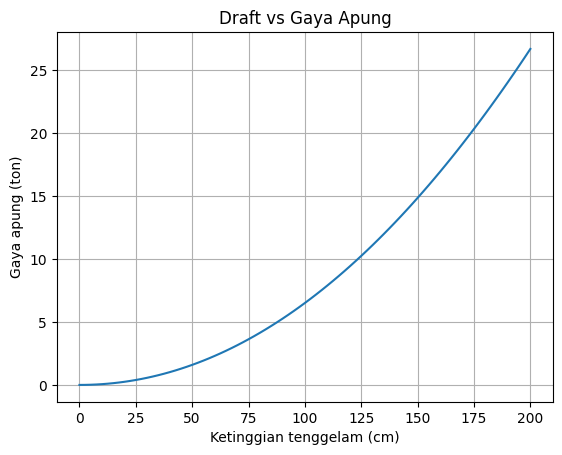

In [5]:
def V_sub(d):
    """Volume tercelup pada draft d (m)."""
    if d <= 0: return 0.0
    vp = L_PRISMA*d**2                                     # prisma: segitiga lebar 2d, luas d^2
    xd = np.sqrt(1 - ((2-d)/2)**2)                         # batas x di buritan yang tercelup
    vb = simpson(lambda x: np.clip(d - h_k(x), 0, None)**2, 0, xd) if xd > 0 else 0.0
    return vp + vb

d_arr = np.linspace(0, 2, 81)
F_arr = np.array([RHO*V_sub(d)/1000 for d in d_arr])
plt.plot(d_arr*100, F_arr); plt.grid()
plt.xlabel("Ketinggian tenggelam (cm)"); plt.ylabel("Gaya apung (ton)")
plt.title("Draft vs Gaya Apung"); plt.show()

**Kesimpulan dan Interpretasi**:

Nilai gaya apung pada beberapa kedalaman: ±1,59 ton (50 cm), ±6,50 ton (100 cm), ±14,84 ton (150 cm), dan 26,67 ton (200 cm).

Kurva **tidak linear** (melengkung naik) karena penampang lambung berbentuk V yang makin lebar ke atas, sehingga setiap tambahan kedalaman menambah volume tercelup lebih besar daripada sebelumnya. Separuh bagian bawah lambung (0–100 cm) hanya menyumbang sekitar 24% dari kapasitas apung maksimum, sedangkan sisanya berasal dari separuh bagian atas.

## Soal 3 – Center of buoyancy dari lantai kapal

**Diketahui**
- Kondisi lambung tercelup penuh ($d = 2$ m), yaitu saat gaya apung maksimum.
- Centroid segitiga berada pada $\tfrac23$ kedalamannya, diukur dari ujung bawah (lunas).

**Ditanya**
Tinggi *center of buoyancy* (CB) dari lantai kapal, dalam cm.

**Dijawab**
CB adalah pusat volume air yang dipindahkan, dihitung sebagai rata-rata berbobot volume:
$$\bar z_B=\frac{\int z\,dV}{V}=\frac{\sum V_i\,\bar z_i}{\sum V_i}$$
1. Prisma: $\bar z_p=\tfrac23 d$ dan momen $M_p = V_p\,\bar z_p$.
2. Buritan: centroid tiap irisan $\bar z(x)=h_k(x)+\tfrac23\big(d-h_k(x)\big)$, sehingga momen $M_b=\int_0^{x_d}(d-h_k)^2\,\bar z(x)\,dx$.
3. $\bar z_B=\dfrac{M_p+M_b}{V_{sub}(d)}$.

In [6]:
def CB(d):
    """Tinggi center of buoyancy dari lunas (m) pada draft d."""
    xd = np.sqrt(1 - ((2-d)/2)**2)
    mp = L_PRISMA*d**2*(2*d/3)                             # momen prisma (centroid segitiga 2/3 d dari apex)
    mb = simpson(lambda x: np.clip(d-h_k(x),0,None)**2*(h_k(x) + 2*np.clip(d-h_k(x),0,None)/3), 0, xd)
    return (mp + mb)/V_sub(d)
print("Center of buoyancy (penuh) =", round(CB(2.0)*100,2), "cm")

Center of buoyancy (penuh) = 134.11 cm


**Kesimpulan dan Interpretasi**:

**Center of buoyancy berada pada ketinggian ±134,11 cm dari lantai kapal.**

Nilai ini setara sekitar 67% dari tinggi lambung (200 cm), yaitu berada di atas titik tengah. Hal ini wajar karena lambung berbentuk V sehingga volume air yang dipindahkan lebih banyak terkumpul di bagian atas yang lebih lebar. Angka ini berlaku untuk kondisi tercelup penuh; pada draft yang lebih dangkal, CB akan berada lebih rendah.

## Soal 4 – Massa total kapal (baja 160 kg/m², termasuk dek)

**Diketahui**
- Berat jenis baja (massa per luas pelat) $\sigma = 160$ kg/m², termasuk dek atas.
- Pelat baja terdiri dari: dua sisi miring prisma, pelat depan haluan, dek, dan dua sisi miring buritan.

**Ditanya**
Massa total kapal $M_{kapal}$ (tanpa muatan).

**Dijawab**
1. Sisi miring prisma: $A_s = 2\,L\,\sqrt{2^2+2^2}$.
2. Pelat depan haluan (segitiga): $A_h = \tfrac12 B D$.
3. Dek: $A_d = B\,L+\int_0^1 2\,t(x)\,dx$, yaitu persegi panjang ditambah bagian buritan yang lebarnya $2t(x)$.
4. Sisi miring buritan: permukaan $z=h_k(x)+w$ memiliki elemen luas $dA=\sqrt{2+h_k'(x)^2}\,dw\,dx$, sehingga $A_{bs}=2\int_0^1 2\sqrt{2+2x^2}\,dx$.
5. Luas total $A_{tot}=A_s+A_h+A_d+A_{bs}$, lalu $M_{kapal}=\sigma\,A_{tot}$.

In [7]:
A_sisi   = 2*L_PRISMA*np.hypot(2, 2)                       # 2 dinding miring prisma
A_haluan = 0.5*LEBAR*DALAM                                 # pelat depan segitiga (anggap tertutup)
A_dek    = LEBAR*L_PRISMA + simpson(lambda x: 2*t_(x), 0, 1)
A_bsisi  = 2*simpson(lambda x: 2*np.sqrt(2 + 2*x**2), 0, 1)  # dinding miring buritan
A_tot    = A_sisi + A_haluan + A_dek + A_bsisi
M_kapal  = ST*A_tot
print("Luas baja =", round(A_tot,3), "m2")
print("Massa kapal =", round(M_kapal,1), "kg =", round(M_kapal/1000,3), "ton")

Luas baja = 71.576 m2
Massa kapal = 11452.1 kg = 11.452 ton


**Kesimpulan dan Interpretasi**:

Luas pelat baja total adalah **71,576 m²** (sisi prisma 33,94; haluan 4,00; dek 27,14; sisi buritan 6,49), sehingga **massa kapal $= 11.452$ kg ≈ 11,45 ton**.

Massa kapal kosong ini sekitar 43% dari gaya apung maksimum (26,67 ton). Dengan demikian, sisa kapasitas muatan yang masih dapat ditanggung kapal agar tetap mengapung adalah sekitar 15,2 ton.

## Soal 5 – Kedalaman kapal tenggelam (root finding)
Syarat apung: gaya apung = berat total → $\rho V_{sub}(d) = M_{total}$

**Diketahui**
- Massa muatan $= 040 \times 100 = 4000$ ton.
- Massa kapal $M_{kapal} = 11{,}452$ ton (Soal 4).
- Gaya apung maksimum $= 26{,}667$ ton (Soal 1).

**Ditanya**
Kedalaman kapal yang tenggelam (draft) $d$.

**Dijawab**
1. Massa total: $M_{total}=M_{kapal}+M_{muatan}$.
2. Syarat terapung (kesetimbangan gaya): $\rho\,V_{sub}(d)=M_{total}$. Persamaan ini dicari akarnya secara numerik dengan metode *brentq* pada selang $0<d\le 2$ m.
3. Akar hanya ada jika $M_{total}\le \rho V_{total}$. Jika $M_{total}>\rho V_{total}$, tidak ada $d\le 2$ m yang memenuhi sehingga kapal tenggelam.

In [9]:
M_total = M_kapal + MUATAN_KG
print("Massa muatan =", MUATAN_TON, "ton | Massa total =", round(M_total/1000,3), "ton")
if M_total > RHO*V_total:
    print("KAPALNYA TENGGELAM! Massa total", round(M_total/1000,2), "ton > gaya apung maksimum", round(RHO*V_total/1000,2), "ton")
    print("Muatan maksimum agar masih mengapung =", round((RHO*V_total - M_kapal)/1000,3), "ton")
    print("Kedalaman tenggelam = 200 cm (seluruh badan kapal sudah di bawah air, tidak ada akar d <= 200 cm)")
else:
    d_eq = brentq(lambda d: RHO*V_sub(d) - M_total, 1e-6, 2.0)
    print("Kedalaman tercelup =", round(d_eq*100,2), "cm")

Massa muatan = 4000.0 ton | Massa total = 4011.452 ton
KAPALNYA TENGGELAM! Massa total 4011.45 ton > gaya apung maksimum 26.67 ton
Muatan maksimum agar masih mengapung = 15.215 ton
Kedalaman tenggelam = 200 cm (seluruh badan kapal sudah di bawah air, tidak ada akar d <= 200 cm)


**Kesimpulan dan Interpretasi**:

Massa total $= 4011{,}452$ ton, jauh lebih besar daripada gaya apung maksimum $26{,}667$ ton (sekitar 150 kali lipat). Karena itu tidak ditemukan akar pada selang $0<d\le 2$ m.

**Kapal tenggelam seluruhnya (kedalaman tenggelam ≥ 200 cm, seluruh lambung berada di bawah permukaan air).** Muatan maksimum yang masih dapat ditanggung kapal agar mengapung hanyalah sekitar 15,2 ton, sedangkan muatan pada soal adalah 4000 ton. Hasil ini merupakan konsekuensi langsung dari angka pada soal dan dimensi kapal.

## Soal 6 – Kurva ketinggian (x) vs massa akumulatif muatan (y)

**Diketahui**
- Tinggi muatan $h_{beban}=200-\text{NPM}=200-40=160$ cm.
- Massa muatan $M=4000$ ton, terdistribusi rata secara vertikal.
- Muatan berada di atas dek, yaitu dari $z=200$ cm sampai $z=200+160=360$ cm.

**Ditanya**
Kurva ketinggian dari lantai kapal $z$ (sumbu x) terhadap massa akumulatif muatan $m(z)$ (sumbu y).

**Dijawab**
Massa per satuan tinggi (seragam): $\lambda=\dfrac{M}{h_{beban}}=\dfrac{4000}{160}=25$ ton/cm. Massa akumulatif dari dasar sampai ketinggian $z$:
$$m(z)=\begin{cases}0, & z<200\\[2pt] \lambda\,(z-200), & 200\le z\le 360\\[2pt] M, & z>360\end{cases}$$

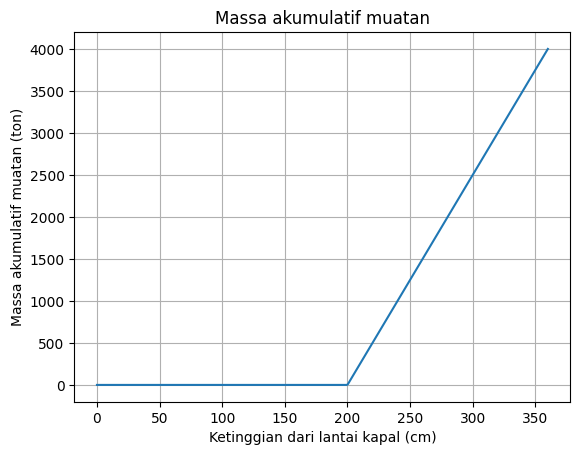

In [10]:
h_beban = 200 - NPM3                                       # cm
z = np.linspace(0, 200 + h_beban, 400)                     # tinggi dari lantai kapal (cm)
m_akum = np.clip((z-200)/h_beban, 0, 1)*MUATAN_TON         # ton; 0 di bawah dek, naik linear, lalu konstan
plt.plot(z, m_akum); plt.grid()
plt.xlabel("Ketinggian dari lantai kapal (cm)"); plt.ylabel("Massa akumulatif muatan (ton)")
plt.title("Massa akumulatif muatan"); plt.show()

**Kesimpulan dan Interpretasi**:

Kurva terdiri dari tiga bagian: **datar di 0 ton** (z < 200 cm, di bawah dek tidak ada muatan), **naik linear** dengan kemiringan 25 ton/cm (200–360 cm, tempat muatan berada), lalu **datar di 4000 ton** (di atas 360 cm, seluruh muatan sudah terhitung).

Garis lurus pada bagian tengah menunjukkan bahwa muatan tersebar merata, sehingga setiap kenaikan 1 cm menambah massa yang sama.

## Soal 7 – Center of mass kapal + muatan

**Diketahui**
- Massa kapal (baja) $M_{kapal}=11{,}452$ ton dan massa muatan $M_{muatan}=4000$ ton.
- Pusat massa muatan berada di tengah tingginya: $z_{muatan}=200+\tfrac{160}{2}=280$ cm.
- Pusat massa baja dihitung dari centroid tiap pelat, dibobot luasnya.

**Ditanya**
Tinggi *center of mass* (CoM) kapal beserta muatan dari lantai kapal, dalam cm.

**Dijawab**
1. Centroid tiap bagian baja: sisi miring prisma $=1$ m (tengah kedalaman), pelat depan $=\tfrac43$ m, dek $=2$ m, dan sisi buritan dihitung numerik. Lalu
$$\bar z_{baja}=\frac{\sum A_i\,\bar z_i}{\sum A_i}$$
2. CoM gabungan (rata-rata berbobot massa):
$$\bar z_{CM}=\frac{M_{kapal}\,\bar z_{baja}+M_{muatan}\,\bar z_{muatan}}{M_{kapal}+M_{muatan}}$$

In [11]:
z_bs = 2*simpson(lambda x: 2*np.sqrt(2+2*x**2)*(2-np.sqrt(1-x**2)), 0, 1)/A_bsisi   # m
z_baja = (A_sisi*1.0 + A_haluan*(4/3) + A_dek*2.0 + A_bsisi*z_bs)/A_tot             # m
z_muat = 200 + h_beban/2                                   # cm
z_cm = (M_kapal*z_baja*100 + MUATAN_KG*z_muat)/M_total
print("CoM baja   =", round(z_baja*100,2), "cm")
print("CoM muatan =", z_muat, "cm")
print("CoM total  =", round(z_cm,2), "cm dari lantai kapal")

CoM baja   = 141.95 cm
CoM muatan = 280.0 cm
CoM total  = 279.61 cm dari lantai kapal


**Kesimpulan dan Interpretasi**:

CoM baja berada di 141,95 cm dan CoM muatan di 280 cm, sehingga **CoM total kapal beserta muatan berada pada ±279,61 cm dari lantai kapal**.

Nilai ini hampir sama dengan CoM muatan karena muatan mencakup sekitar 99,7% dari massa total, sehingga massa baja nyaris tidak menggeser titik berat gabungan. Titik berat berada sekitar 80 cm di atas dek (200 cm), jauh lebih tinggi daripada center of buoyancy (134,11 cm).

## Kesimpulan Umum
| No | Besaran | Hasil |
|---|---|---|
| 1 | Volume total / gaya apung maksimum | 26,667 m³ / 26,667 ton-gaya |
| 2 | Kurva draft vs gaya apung | Non-linear, naik dari 0 sampai 26,67 ton |
| 3 | Center of buoyancy (tercelup penuh) | ±134,11 cm |
| 4 | Massa total kapal (baja) | ±11.452 kg (11,45 ton) |
| 5 | Kedalaman tenggelam | Kapal tenggelam seluruhnya (4011,45 ton > 26,67 ton) |
| 6 | Kurva massa akumulatif muatan | Datar–naik linear (200–360 cm)–datar, maksimum 4000 ton |
| 7 | Center of mass kapal + muatan | ±279,61 cm |

Seluruh perhitungan menggunakan integral numerik Simpson 1/3 dan pencarian akar metode *brentq* sebagai penerapan analisis numerik pada masalah nyata.